# Team 11 · Notebook 02: Gold Layer and Exploratory Data Analysis
**Project:** Road Accident Risk Pipeline for usage-based auto insurance  
**Input:** `workspace.accidents.silver_accidents` (7,728,394 cleaned rows from Notebook 01)  
**Output:** 7 gold tables that answer our business questions, a gold quality check, and 6 EDA charts saved for the dashboard and presentation.

| Business question (from Checkpoint 2) | Gold table(s) |
|---|---|
| Q1. Which states and cities have the most accidents, and what share are severe? | `gold_state_summary`, `gold_city_summary` |
| Q2. At which hours, weekdays and months do accidents peak? | `gold_time_patterns` |
| Q3. How do weather and road features change the share of severe accidents? | `gold_weather_severity`, `gold_road_feature_severity` |
| Headline numbers and model input | `gold_kpis`, `gold_monthly_state_volume` |

**Gaps this closes:** Spark/PySpark on large data, lakehouse layers (gold), optimising data workflows (liquid clustering), data quality.

## 0. Setup
A **severe** accident means severity 3 or 4 (the `is_severe` column built in silver). All charts are saved as PNG files in the `figures` volume, so we can download them for the presentation.

In [0]:
from pyspark.sql import functions as F, Window
import time, os
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

CATALOG = "workspace"
SCHEMA  = "accidents"
FIG_DIR = "/Volumes/workspace/accidents/figures"
MIN_CITY_ACCIDENTS = 1000   # cities with fewer accidents are left out of the city ranking

def tbl(name):
    return f"{CATALOG}.{SCHEMA}.{name}"

try:
    spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG}.{SCHEMA}.figures")
except Exception as e:
    print("Volume not created here:", str(e)[:120])
os.makedirs(FIG_DIR, exist_ok=True)

# One chart style for the whole project
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#9a9893", "#1f1f1e", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#c9c7c1", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebe9e4", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
def save(fig, name):
    fig.tight_layout()
    path = f"{FIG_DIR}/{name}.png"
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    print("Saved:", path)

silver = spark.table(tbl("silver_accidents"))
silver_rows = silver.count()
print(f"Silver rows: {silver_rows:,}")

Silver rows: 7,728,394


## 1. Optimise the silver table (liquid clustering)
*Closes the gap: monitoring and optimising data workflows.*

Most of our queries filter by **year** and **state**. In Checkpoint 2 we planned to partition silver by these columns. Databricks now recommends **liquid clustering** instead of fixed partitions: it groups rows with the same year and state into the same files, so a query for one state and year reads far fewer files. We time the same query before and after.

In [0]:
def timed_query():
    t = time.time()
    n = (spark.table(tbl("silver_accidents"))
              .filter((F.col("State") == "CA") & (F.col("year") == 2022))
              .count())
    return round(time.time() - t, 2), n

before_s, rows_ca = timed_query()
try:
    spark.sql(f"ALTER TABLE {tbl('silver_accidents')} CLUSTER BY (year, State)")
    spark.sql(f"OPTIMIZE {tbl('silver_accidents')}")
    clustered = True
except Exception as e:
    clustered = False
    print("Clustering not applied here:", str(e)[:150])
after_s, _ = timed_query()

print(f"Query: accidents in California in 2022 = {rows_ca:,}")
print(f"Time before clustering: {before_s}s | after: {after_s}s | clustering applied: {clustered}")
try:
    display(spark.sql(f"DESCRIBE DETAIL {tbl('silver_accidents')}").select("numFiles", "sizeInBytes", "clusteringColumns"))
except Exception as e:
    print("DESCRIBE DETAIL not available here:", str(e)[:120])

Query: accidents in California in 2022 = 375,913
Time before clustering: 4.79s | after: 0.79s | clustering applied: True


numFiles,sizeInBytes,clusteringColumns
7,380402642,"List(year, State)"


## 2. Build the gold tables
Each gold table is a small, business-ready summary of the 7.7 million silver rows. Shares are in percent and rounded to 2 decimals.

In [0]:
severe = F.col("is_severe").cast("int")

def write_gold(df, name):
    df.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(tbl(name))
    n = spark.table(tbl(name)).count()
    print(f"{name:<28} {n:>8,} rows")

# Headline numbers (one row)
gold_kpis = silver.agg(
    F.count("*").alias("total_accidents"),
    F.sum(severe).alias("severe_accidents"),
    F.round(100 * F.avg(severe), 2).alias("severe_share_pct"),
    F.countDistinct("State").alias("states"),
    F.countDistinct("State", "City").alias("cities"),
    F.min("start_time").alias("first_accident"),
    F.max("start_time").alias("last_accident"),
    F.round(F.percentile_approx("duration_min", 0.5), 1).alias("median_duration_min"),
)
write_gold(gold_kpis, "gold_kpis")

# Q1: by state
state_w = Window.orderBy(F.desc("accidents"))
gold_state = (silver.groupBy("State").agg(
        F.count("*").alias("accidents"),
        F.sum(severe).alias("severe_accidents"),
        F.round(100 * F.avg(severe), 2).alias("severe_share_pct"),
        F.round(100 * F.avg((F.col("Sunrise_Sunset") == "Night").cast("int")), 2).alias("night_share_pct"),
        F.round(F.percentile_approx("duration_min", 0.5), 1).alias("median_duration_min"))
    .withColumn("rank_by_accidents", F.row_number().over(state_w)))
write_gold(gold_state, "gold_state_summary")

# Q1: by city (only cities with enough accidents to compare fairly)
gold_city = (silver.groupBy("State", "City").agg(
        F.count("*").alias("accidents"),
        F.sum(severe).alias("severe_accidents"),
        F.round(100 * F.avg(severe), 2).alias("severe_share_pct"))
    .filter(F.col("accidents") >= MIN_CITY_ACCIDENTS))
write_gold(gold_city, "gold_city_summary")

# Q2: by time
gold_time = silver.groupBy("year", "month", "weekday_num", "weekday", "hour").agg(
    F.count("*").alias("accidents"), F.sum(severe).alias("severe_accidents"))
write_gold(gold_time, "gold_time_patterns")

# Q3: by weather
gold_weather = silver.groupBy("weather_category").agg(
    F.count("*").alias("accidents"),
    F.sum(severe).alias("severe_accidents"),
    F.round(100 * F.avg(severe), 2).alias("severe_share_pct"),
    F.round(F.avg("Visibility_mi"), 2).alias("avg_visibility_mi"),
    F.round(F.avg("Temperature_F"), 1).alias("avg_temperature_f"))
write_gold(gold_weather, "gold_weather_severity")

# Q3: by road feature (with the feature vs without it)
road_features = ["Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit", "Railway",
                 "Roundabout", "Station", "Stop", "Traffic_Calming", "Traffic_Signal", "Turning_Loop"]
stack = "stack({}, {}) as (road_feature, present)".format(
    len(road_features), ", ".join(f"'{c}', coalesce(`{c}`, false)" for c in road_features))
long = silver.select("is_severe", F.expr(stack))
gold_road = (long.groupBy("road_feature").agg(
        F.sum(F.col("present").cast("int")).alias("accidents_with_feature"),
        F.round(100 * F.avg(F.when(F.col("present"), severe)), 2).alias("severe_share_with_pct"),
        F.round(100 * F.avg(F.when(~F.col("present"), severe)), 2).alias("severe_share_without_pct"))
    .withColumn("difference_pts", F.round(F.col("severe_share_with_pct") - F.col("severe_share_without_pct"), 2)))
write_gold(gold_road, "gold_road_feature_severity")

# Model input: accidents per state per month (used by the forecasting model in Notebook 03)
gold_monthly = (silver.groupBy("State", "year", "month").agg(
        F.count("*").alias("accidents"), F.sum(severe).alias("severe_accidents"))
    .withColumn("year_month", F.make_date("year", "month", F.lit(1))))
write_gold(gold_monthly, "gold_monthly_state_volume")

gold_kpis                           1 rows


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


gold_state_summary                 49 rows
gold_city_summary               1,181 rows
gold_time_patterns             14,411 rows
gold_weather_severity               8 rows
gold_road_feature_severity         13 rows
gold_monthly_state_volume       3,957 rows


## 3. Gold quality checks
The gold tables must add back up to the silver table: if any accidents were lost or counted twice, the totals would not match. Results are added to the same `dq_log` table we started in Checkpoint 3.

In [0]:
from datetime import datetime
run_ts = datetime.now()
checks = []
def total(name, col="accidents"):
    return spark.table(tbl(name)).agg(F.sum(col)).first()[0] or 0

for name in ["gold_state_summary", "gold_time_patterns", "gold_weather_severity", "gold_monthly_state_volume"]:
    t = total(name)
    checks.append((run_ts, 1.0, "gold", f"{name}_total_equals_silver", float(t),
                   "PASS" if t == silver_rows else "WARN", f"silver rows = {silver_rows}"))
kpi_total = spark.table(tbl("gold_kpis")).first()["total_accidents"]
checks.append((run_ts, 1.0, "gold", "gold_kpis_total_equals_silver", float(kpi_total),
               "PASS" if kpi_total == silver_rows else "WARN", ""))
bad_share = spark.table(tbl("gold_state_summary")).filter(~F.col("severe_share_pct").between(0, 100)).count()
checks.append((run_ts, 1.0, "gold", "severe_share_between_0_and_100", float(bad_share),
               "PASS" if bad_share == 0 else "WARN", "states with a share outside 0-100"))

dq = spark.createDataFrame(checks,
    "run_ts timestamp, sample_fraction double, layer string, check_name string, value double, status string, note string")
dq.write.mode("append").saveAsTable(tbl("dq_log"))
display(dq)

run_ts,sample_fraction,layer,check_name,value,status,note
2026-11-23T17:10:14.478Z,1.0,gold,gold_state_summary_total_equals_silver,7728394.0,PASS,silver rows = 7728394
2026-11-23T17:10:14.478Z,1.0,gold,gold_time_patterns_total_equals_silver,7728394.0,PASS,silver rows = 7728394
2026-11-23T17:10:14.478Z,1.0,gold,gold_weather_severity_total_equals_silver,7728394.0,PASS,silver rows = 7728394
2026-11-23T17:10:14.478Z,1.0,gold,gold_monthly_state_volume_total_equals_silver,7728394.0,PASS,silver rows = 7728394
2026-11-23T17:10:14.478Z,1.0,gold,gold_kpis_total_equals_silver,7728394.0,PASS,
2026-11-23T17:10:14.478Z,1.0,gold,severe_share_between_0_and_100,0.0,PASS,states with a share outside 0-100


## 4. Exploratory data analysis (EDA)
Six charts that answer our business questions. Each one is also rebuilt in the Databricks dashboard and used in the presentation.

In [0]:
# Headline numbers
k = spark.table(tbl("gold_kpis")).first()
print(f"Total accidents      : {k['total_accidents']:,}")
print(f"Severe accidents     : {k['severe_accidents']:,} ({k['severe_share_pct']}%)")
print(f"States / cities      : {k['states']} / {k['cities']:,}")
print(f"Period               : {k['first_accident']} to {k['last_accident']}")
print(f"Median duration (min): {k['median_duration_min']}")

Total accidents      : 7,728,394
Severe accidents     : 1,504,047 (19.46%)
States / cities      : 49 / 20,323
Period               : 2016-01-14 20:18:33 to 2023-03-31 23:30:00
Median duration (min): 74.9


Saved: /Volumes/workspace/accidents/figures/01_severity_distribution.png


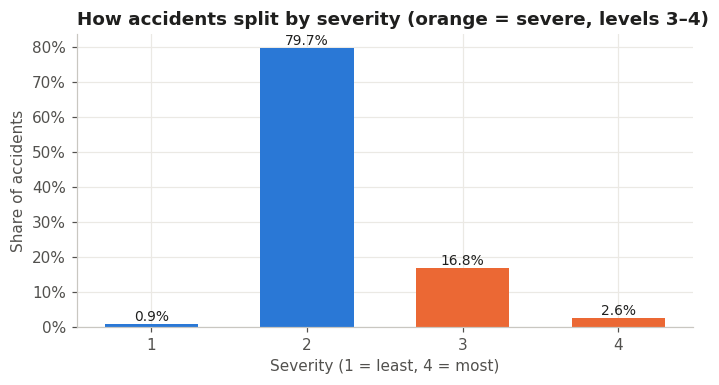

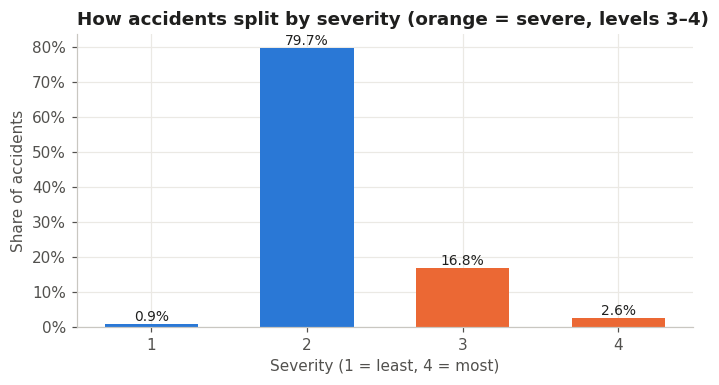

In [0]:
# Chart 1: how accidents split by severity
sev = silver.groupBy("Severity").count().orderBy("Severity").toPandas()
sev["share"] = 100 * sev["count"] / sev["count"].sum()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
colors = [BLUE if s < 3 else ORANGE for s in sev["Severity"]]
bars = ax.bar(sev["Severity"].astype(str), sev["share"], color=colors, width=0.6)
for b, v in zip(bars, sev["share"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}%", ha="center", fontsize=9, color=INK)
ax.set_title("How accidents split by severity (orange = severe, levels 3–4)")
ax.set_xlabel("Severity (1 = least, 4 = most)"); ax.set_ylabel("Share of accidents")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
save(fig, "01_severity_distribution"); display(fig)

Saved: /Volumes/workspace/accidents/figures/02_accidents_per_year.png


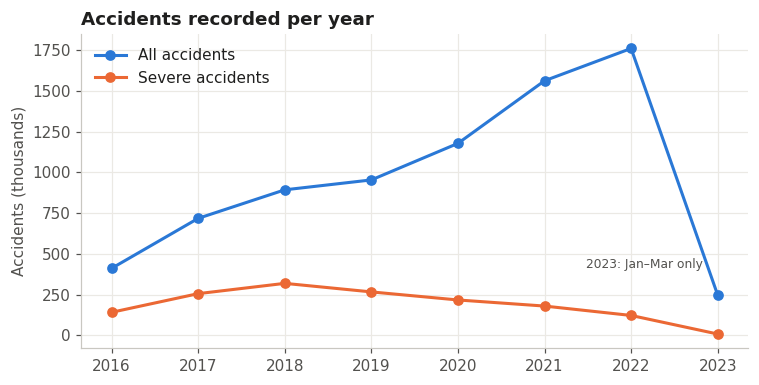

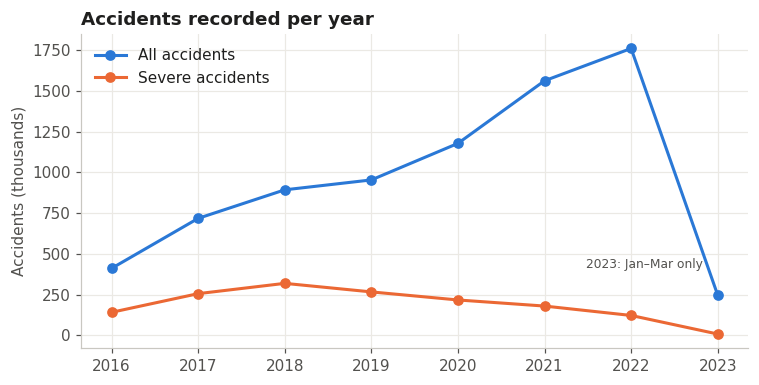

In [0]:
# Chart 2: accidents per year (2023 holds only January to March)
yr = (spark.table(tbl("gold_time_patterns")).groupBy("year")
      .agg(F.sum("accidents").alias("accidents"), F.sum("severe_accidents").alias("severe"))
      .orderBy("year").toPandas())
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(yr["year"], yr["accidents"] / 1e3, color=BLUE, lw=2, marker="o", ms=6, label="All accidents")
ax.plot(yr["year"], yr["severe"] / 1e3, color=ORANGE, lw=2, marker="o", ms=6, label="Severe accidents")
ax.set_title("Accidents recorded per year")
ax.set_ylabel("Accidents (thousands)"); ax.set_xticks(yr["year"])
ax.legend(frameon=False)
ax.annotate("2023: Jan–Mar only", xy=(yr["year"].iloc[-1], yr["accidents"].iloc[-1] / 1e3),
            xytext=(-10, 18), textcoords="offset points", ha="right", fontsize=8, color=MUTED)
save(fig, "02_accidents_per_year"); display(fig)

Saved: /Volumes/workspace/accidents/figures/03_hour_weekday_heatmap.png


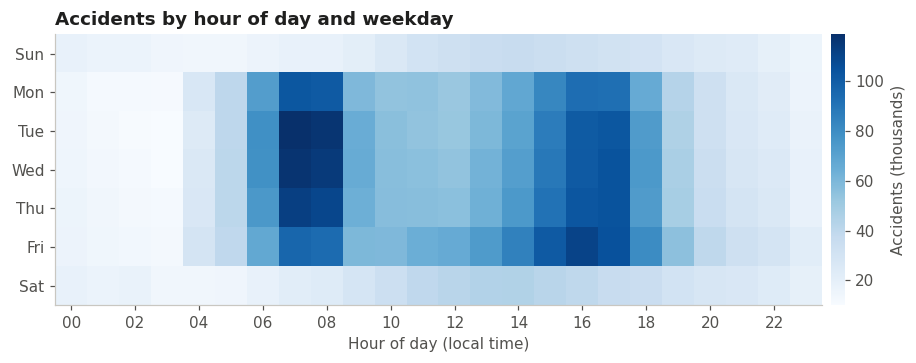

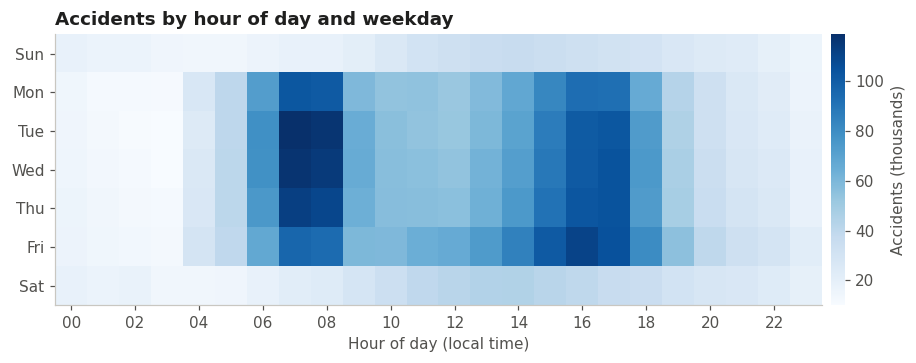

In [0]:
# Chart 3: hour x weekday heatmap
import numpy as np
hw = (spark.table(tbl("gold_time_patterns")).groupBy("weekday_num", "hour")
      .agg(F.sum("accidents").alias("accidents")).toPandas()
      .pivot(index="weekday_num", columns="hour", values="accidents").reindex(index=range(1, 8), columns=range(24)).fillna(0))
fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(hw.values / 1e3, aspect="auto", cmap="Blues")
ax.set_yticks(range(7)); ax.set_yticklabels(["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"])
ax.set_xticks(range(0, 24, 2)); ax.set_xticklabels([f"{h:02d}" for h in range(0, 24, 2)])
ax.set_xlabel("Hour of day (local time)"); ax.grid(False)
ax.set_title("Accidents by hour of day and weekday")
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.set_label("Accidents (thousands)", color=MUTED); cb.outline.set_visible(False)
save(fig, "03_hour_weekday_heatmap"); display(fig)

Saved: /Volumes/workspace/accidents/figures/04_top_states.png


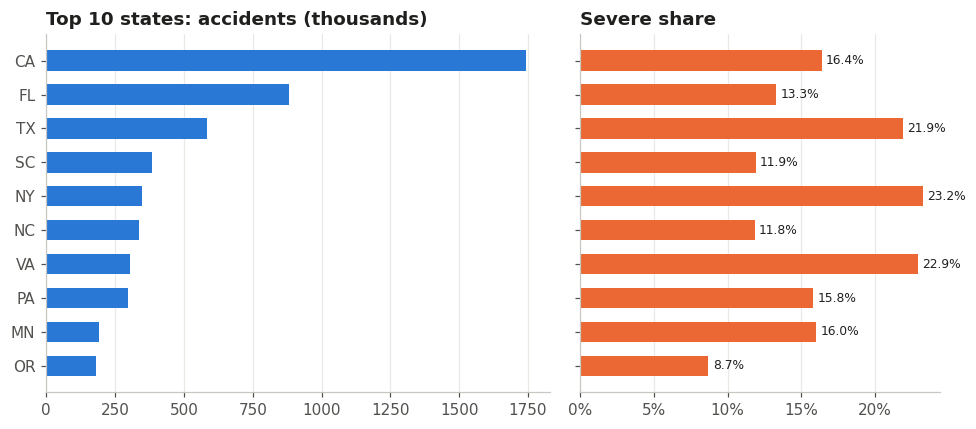

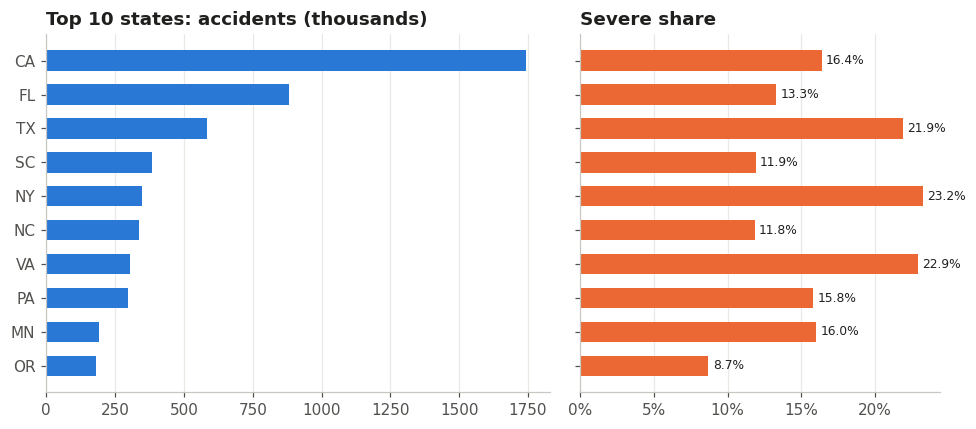

In [0]:
# Chart 4: top 10 states by number of accidents, with their severe share
st = spark.table(tbl("gold_state_summary")).orderBy(F.desc("accidents")).limit(10).toPandas()[::-1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 4), sharey=True, gridspec_kw={"width_ratios": [1.4, 1]})
a1.barh(st["State"], st["accidents"] / 1e3, color=BLUE, height=0.6)
a1.set_title("Top 10 states: accidents (thousands)"); a1.grid(axis="y", visible=False)
a2.barh(st["State"], st["severe_share_pct"], color=ORANGE, height=0.6)
a2.set_title("Severe share"); a2.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); a2.grid(axis="y", visible=False)
for y, v in enumerate(st["severe_share_pct"]):
    a2.text(v + 0.3, y, f"{v:.1f}%", va="center", fontsize=8, color=INK)
save(fig, "04_top_states"); display(fig)

Saved: /Volumes/workspace/accidents/figures/05_severity_by_weather.png


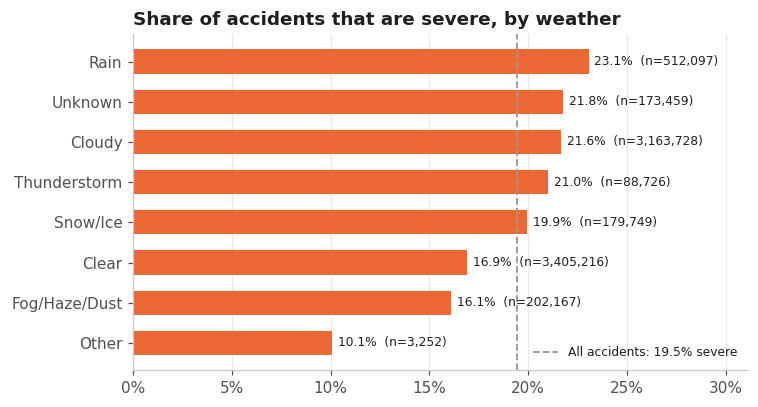

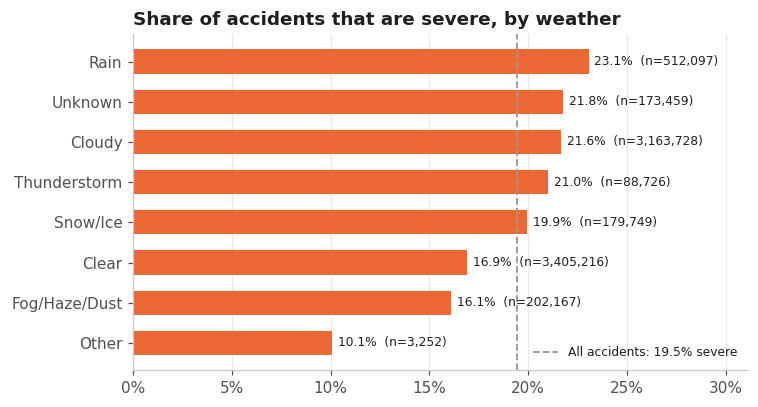

In [0]:
# Chart 5: severe share by weather
wt = spark.table(tbl("gold_weather_severity")).orderBy("severe_share_pct").toPandas()
overall = spark.table(tbl("gold_kpis")).first()["severe_share_pct"]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(wt["weather_category"], wt["severe_share_pct"], color=ORANGE, height=0.6)
ax.axvline(overall, color=GREY, ls="--", lw=1.2, label=f"All accidents: {overall:.1f}% severe")
ax.legend(frameon=False, loc="lower right", fontsize=8)
for y, (v, n) in enumerate(zip(wt["severe_share_pct"], wt["accidents"])):
    ax.text(v + 0.3, y, f"{v:.1f}%  (n={n:,})", va="center", fontsize=8, color=INK)
ax.set_title("Share of accidents that are severe, by weather")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.grid(axis="y", visible=False)
ax.set_xlim(0, wt["severe_share_pct"].max() * 1.35)
save(fig, "05_severity_by_weather"); display(fig)

Saved: /Volumes/workspace/accidents/figures/06_road_features.png


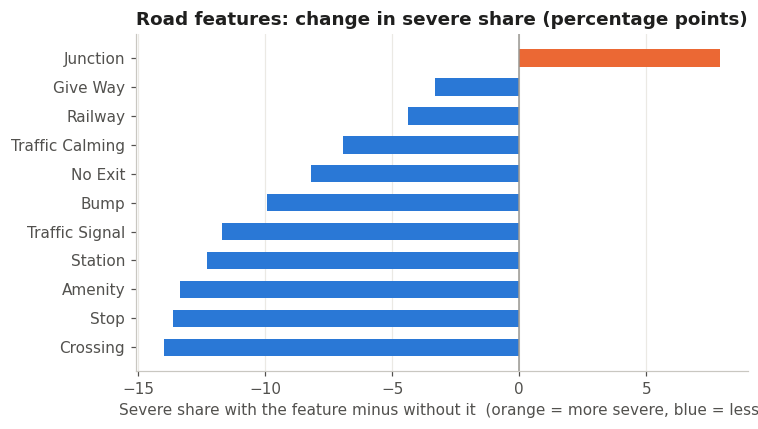

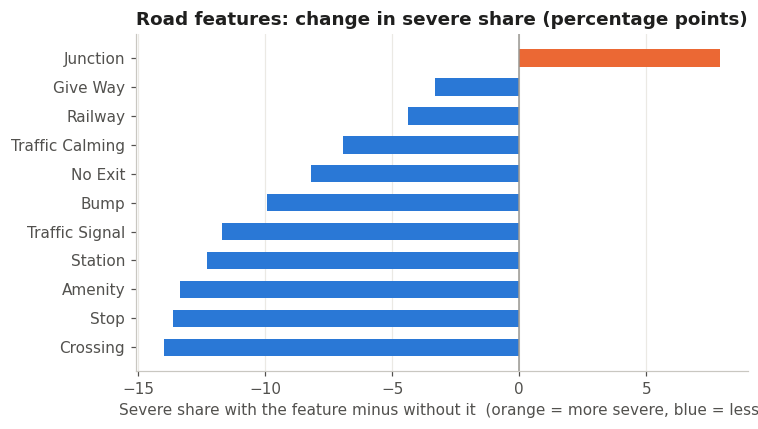

In [0]:
# Chart 6: road features - severe share with the feature minus without it
rd = (spark.table(tbl("gold_road_feature_severity")).filter(F.col("accidents_with_feature") >= 1000)
      .orderBy("difference_pts").toPandas())
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(rd["road_feature"].str.replace("_", " "), rd["difference_pts"],
        color=[ORANGE if v > 0 else BLUE for v in rd["difference_pts"]], height=0.6)
ax.axvline(0, color=GREY, lw=1)
ax.set_title("Road features: change in severe share (percentage points)")
ax.set_xlabel("Severe share with the feature minus without it  (orange = more severe, blue = less)")
ax.grid(axis="y", visible=False)
save(fig, "06_road_features"); display(fig)

## 5. What the gold layer tells us
Run the cell below and use its output in the presentation and final report. Each line is a finding the dashboard shows visually.

In [0]:
st_all = spark.table(tbl("gold_state_summary"))
top_vol = st_all.orderBy(F.desc("accidents")).first()
big = st_all.filter(F.col("accidents") >= 10000)
top_sev = big.orderBy(F.desc("severe_share_pct")).first() if big.count() else st_all.orderBy(F.desc("severe_share_pct")).first()
peak = (spark.table(tbl("gold_time_patterns")).groupBy("weekday", "hour").agg(F.sum("accidents").alias("a"))
        .orderBy(F.desc("a")).first())
w_hi = spark.table(tbl("gold_weather_severity")).filter(F.col("weather_category") != "Unknown").orderBy(F.desc("severe_share_pct")).first()
r_hi = spark.table(tbl("gold_road_feature_severity")).filter(F.col("accidents_with_feature") >= 1000).orderBy(F.desc("difference_pts")).first()
r_lo = spark.table(tbl("gold_road_feature_severity")).filter(F.col("accidents_with_feature") >= 1000).orderBy("difference_pts").first()
print(f"1. Most accidents: {top_vol['State']} ({top_vol['accidents']:,}); highest severe share among states with 10,000+ accidents: {top_sev['State']} ({top_sev['severe_share_pct']}%).")
print(f"2. Busiest single slot: {peak['weekday']} at {peak['hour']:02d}:00 ({peak['a']:,} accidents).")
print(f"3. Most severe weather: {w_hi['weather_category']} ({w_hi['severe_share_pct']}% severe vs {overall}% overall).")
print(f"4. Road feature with the biggest rise in severe share: {r_hi['road_feature']} (+{r_hi['difference_pts']} pts); biggest fall: {r_lo['road_feature']} ({r_lo['difference_pts']} pts).")

1. Most accidents: CA (1,741,433); highest severe share among states with 10,000+ accidents: RI (46.24%).
2. Busiest single slot: Tue at 07:00 (118,920 accidents).
3. Most severe weather: Rain (23.06% severe vs 19.46% overall).
4. Road feature with the biggest rise in severe share: Junction (+7.91 pts); biggest fall: Crossing (-14.0 pts).
